In [1]:
import pandas as pd 

In [2]:
games = pd.read_csv("../data/raw/MRegularSeasonCompactResults.csv") 
games.head() 

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT
0,1985,20,1228,81,1328,64,N,0
1,1985,25,1106,77,1354,70,H,0
2,1985,25,1112,63,1223,56,H,0
3,1985,25,1165,70,1432,54,H,0
4,1985,25,1192,86,1447,74,H,0


In [4]:
games.shape

(198577, 8)

print(games['Season'].min(), games['Season'].max()) 

There are 198,577 rows of game level data with 8 simple columns. The data starts in 1985 and ranges through the latest 2025-26 season.

In [7]:
games['Season'].value_counts().sort_index()

Season
1985    3737
1986    3783
1987    3915
1988    3955
1989    4037
1990    4045
1991    4123
1992    4127
1993    3982
1994    4060
1995    4077
1996    4122
1997    4155
1998    4167
1999    4222
2000    4519
2001    4467
2002    4555
2003    4616
2004    4571
2005    4675
2006    4757
2007    5043
2008    5163
2009    5249
2010    5263
2011    5246
2012    5253
2013    5320
2014    5362
2015    5354
2016    5369
2017    5395
2018    5405
2019    5463
2020    5328
2021    3855
2022    5345
2023    5602
2024    5607
2025    5641
2026    5647
Name: count, dtype: int64

There is a clear increasing trend between time and games played in a season. 

In [13]:
home_away = games[games['WLoc'].isin(['H', 'A'])]

In [16]:
home_by_season = home_away.groupby("Season")["WLoc"].value_counts(normalize=True).unstack() 

In [17]:
home_by_season.tail(26)

WLoc,A,H
Season,,
2001,0.325868,0.674132
2002,0.332596,0.667404
2003,0.330157,0.669843
2004,0.338547,0.661453
2005,0.327432,0.672568
2006,0.335959,0.664041
2007,0.324521,0.675479
2008,0.335981,0.664019
2009,0.336083,0.663917


In [18]:
   pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 16.3 MB/s  0:00:001.8 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 24.8 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 24.3 MB/s  0:00:00 26.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


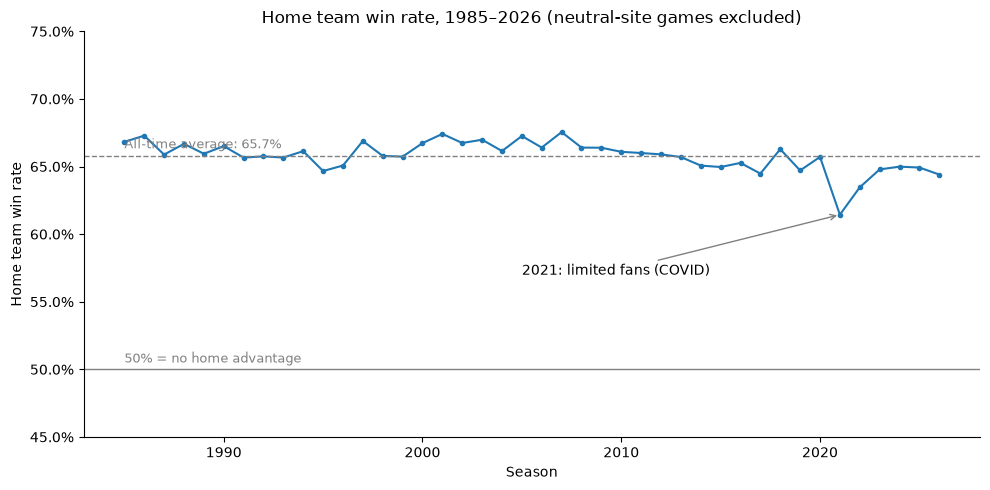

In [28]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

hwp = home_by_season["H"]
overall = (home_away["WLoc"] == "H").mean()  # aggregated home win rate, all seasons

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hwp.index, hwp.values, marker="o", markersize=3)

# Reference lines
ax.axhline(0.5, color="gray", linewidth=1)
ax.text(1985, 0.505, "50% = no home advantage", color="gray", fontsize=9)
ax.axhline(overall, color="gray", linestyle="--", linewidth=1)
ax.text(1985, overall + 0.006, f"All-time average: {overall:.1%}", color="gray", fontsize=9)

# Call out 2021
ax.annotate("2021: limited fans (COVID)",
            xy=(2021, hwp.loc[2021]), xytext=(2005, 0.57),
            arrowprops=dict(arrowstyle="->", color="gray"))

# Axes and labels
ax.set_ylim(0.45, 0.75)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Season")
ax.set_ylabel("Home team win rate")
ax.set_title("Home team win rate, 1985–2026 (neutral-site games excluded)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()